# LW-DETR: float ONNX → Aidge PTQ

This notebook loads the float LW-DETR ONNX model, calibrates it with images through `aidge_quantization`, reports native coverage and tensor dtypes, runs inference, and plots ONNX Runtime versus quantized Aidge detections.

Start with `FAKE_QUANTIZE = True`. This keeps tensors executable as float while applying the requested quantization grid. Set it to `False` to test true integer tensors; unsupported integer CPU kernels will be reported explicitly.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import time
import traceback

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import patches
from PIL import Image
import onnxruntime as ort

import aidge_core
import aidge_onnx
import aidge_backend_cpu

try:
    import aidge_quantization
except ImportError as exc:
    raise ImportError(
        "aidge_quantization is not installed. From the Aidge checkout run: "
        "./setup.sh -m quantization"
    ) from exc

aidge_core.Log.set_console_level(aidge_core.Level.Error)
print("aidge_quantization:", aidge_quantization.__file__)
print("Aidge backends:", aidge_core.Tensor.get_available_backends())

aidge_quantization: /home/tl286648/miniforge3/envs/aidge/lib/python3.12/site-packages/aidge_quantization/__init__.py
Aidge backends: {'cpu', 'export_serialize'}


## Configuration

In [2]:
cwd = Path.cwd().resolve()
if cwd.name == "deploy":
    DEPLOY_DIR = cwd
    REPO_ROOT = cwd.parent
else:
    REPO_ROOT = cwd
    DEPLOY_DIR = REPO_ROOT / "deploy"
DEMO_DIR = REPO_ROOT / "demo"

# Float model (not the .sim.onnx fake-quantized export).
MODEL_PATH = REPO_ROOT / "output" / "onnx_export" / "tiny" / "inference_model.sim.onnx"
IMAGE_DIR = DEMO_DIR / "images"

IMG_SIZE = 640
NB_BITS = 8
NB_CALIBRATION_IMAGES = 8
FAKE_QUANTIZE = True
AIDGE_BACKEND = "cpu"

assert MODEL_PATH.exists(), MODEL_PATH
assert IMAGE_DIR.exists(), IMAGE_DIR
print("model:", MODEL_PATH)
print("images:", IMAGE_DIR)
print("bits:", NB_BITS, "fake quantization:", FAKE_QUANTIZE)

model: /home/tl286648/dev/model/LW-DETR/output/onnx_export/tiny/inference_model.sim.onnx
images: /home/tl286648/dev/model/LW-DETR/demo/images
bits: 8 fake quantization: True


## Images and preprocessing

In [3]:
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32).reshape(3, 1, 1)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32).reshape(3, 1, 1)


def preprocess(image, img_size=IMG_SIZE):
    original_size = image.size
    resized = image.resize((img_size, img_size), Image.BILINEAR)
    array = np.asarray(resized, dtype=np.float32) / 255.0
    chw = np.transpose(array, (2, 0, 1))
    return ((chw - MEAN) / STD)[None].astype(np.float32), original_size


image_paths = []
for pattern in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.webp"):
    image_paths.extend(sorted(IMAGE_DIR.glob(pattern)))
if not image_paths:
    raise FileNotFoundError(f"No images found under {IMAGE_DIR}")

calibration_paths = image_paths[: min(NB_CALIBRATION_IMAGES, len(image_paths))]
test_path = image_paths[min(len(image_paths) - 1, len(calibration_paths))]
test_image = Image.open(test_path).convert("RGB")
input_array, original_size = preprocess(test_image)

print("calibration images:", len(calibration_paths))
print("test image:", test_path.name)
print("input:", input_array.shape, input_array.dtype)

calibration images: 7
test image: objects.jpg
input: (1, 3, 640, 640) float32


## ONNX Runtime float reference

In [4]:
ort_session = ort.InferenceSession(str(MODEL_PATH), providers=["CPUExecutionProvider"])
ort_input_name = ort_session.get_inputs()[0].name
ort_output_names = [output.name for output in ort_session.get_outputs()]


def run_ort(batch):
    return dict(zip(ort_output_names, ort_session.run(None, {ort_input_name: batch})))


t0 = time.perf_counter()
ort_outputs = run_ort(input_array)
print(f"ONNX Runtime: {time.perf_counter() - t0:.3f}s")
for name, value in ort_outputs.items():
    print(name, value.shape, value.dtype, float(value.min()), float(value.max()))

ONNX Runtime: 0.124s
dets (1, 100, 4) float32 0.01784624718129635 0.9995803833007812
labels (1, 100, 91) float32 -10.38261604309082 2.6164002418518066


## Load the float model and report native coverage

In [5]:
float_model = aidge_onnx.load_onnx(str(MODEL_PATH))
# ONNX can contain one-input Concat nodes. They are identities and currently
# confuse Aidge PTQ's merging-node analysis, so remove them first.
aidge_core.recipes.nop_concat(float_model)
# Do not call set_datatype(float32) here. Unlike the homogeneous CNN in the
# official tutorial, LW-DETR has int64 shape/index subgraphs. A global dtype
# conversion changes Expand/Reshape shape inputs to float32 and makes their CPU
# registrar signatures invalid.
# Instead, propagate float32 from the model input through each operator's dtype
# rules. This preserves required int64 shape/index inputs and boolean outputs.
float_model.forward_dtype(dtype=aidge_core.dtype.float32)
float_model.set_backend(AIDGE_BACKEND)
print("Float Aidge graph nodes:", len(float_model.get_nodes()))
aidge_onnx.native_coverage_report(float_model)
print("\nAidge PTQ support report:")
aidge_quantization.quantizability_report(float_model)

Float Aidge graph nodes: 1070
Native operators: 1070 (34 types)
- Add: 132
- Cast: 1
- Concat: 5
- Conv2D: 3
- Div: 25
- Erf: 6
- Exp: 2
- Expand: 1
- Gather: 3
- GatherElements: 1
- GridSample: 3
- LayerNorm: 11
- MatMul: 84
- Mul: 69
- PaddedConv2D: 6
- Pow: 13
- Producer: 444
- ReLU: 9
- ReduceMax: 1
- ReduceMean: 26
- ReduceSum: 3
- Reshape: 70
- Sigmoid: 8
- Slice: 14
- Softmax: 12
- Split: 7
- Sqrt: 13
- Squeeze: 18
- Sub: 17
- Tile: 1
- TopK: 1
- Transpose: 53
- Unsqueeze: 7
- Where: 1
Generic operators: 0 (0 types)
Native types coverage: 100.0% (34/34)
Native operators coverage: 100.0% (1070/1070)

Aidge PTQ support report:
      Graph Quantizability Report       

- [ok] Add x132
- [ok] Concat x5
- [ok] Conv2D x3
- [ok] Div x25
- [ok] Gather x3
- [ok] MatMul x84
- [ok] Mul x69
- [ok] PaddedConv2D x6
- [ok] Producer x444
- [ok] ReLU x9
- [ok] Reshape x70
- [ok] Slice x14
- [ok] Split x7
- [ok] Squeeze x18
- [ok] Sub x17
- [ok] Tile x1
- [ok] Transpose x53
- [!] Sigmoid x8
- [?]

## Dtype reporting helpers

In [6]:
def tensor_dtype(tensor):
    if tensor is None:
        return "None"
    value = tensor.dtype
    return str(value() if callable(value) else value)


def dtype_report(graph, title, show_nodes=False):
    outputs = Counter()
    by_operator = Counter()
    for node in graph.get_ordered_nodes():
        op = node.get_operator()
        node_outputs = []
        for index in range(op.nb_outputs()):
            dtype = tensor_dtype(op.get_output(index))
            outputs[dtype] += 1
            by_operator[(node.type(), dtype)] += 1
            node_outputs.append(dtype)
        if show_nodes:
            print(f"{node.name():90} {node.type():20} {node_outputs}")

    print(f"\n{title}")
    print("Output tensor dtypes:")
    for dtype, count in outputs.most_common():
        print(f"  {dtype:20} {count}")
    print("\nOperator type / output dtype:")
    for (op_type, dtype), count in sorted(by_operator.items()):
        print(f"  {op_type:24} {dtype:16} {count}")
    return outputs, by_operator


float_dtype_summary, _ = dtype_report(float_model, "Before quantization")


Before quantization
Output tensor dtypes:
  dtype.float32        919
  dtype.int64          164
  dtype.boolean        1

Operator type / output dtype:
  Add                      dtype.float32    132
  Cast                     dtype.float32    1
  Concat                   dtype.float32    5
  Conv2D                   dtype.float32    3
  Div                      dtype.float32    25
  Erf                      dtype.float32    6
  Exp                      dtype.float32    2
  Expand                   dtype.int64      1
  Gather                   dtype.float32    3
  GatherElements           dtype.float32    1
  GridSample               dtype.float32    3
  LayerNorm                dtype.float32    11
  MatMul                   dtype.float32    84
  Mul                      dtype.float32    69
  PaddedConv2D             dtype.float32    6
  Pow                      dtype.float32    13
  Producer                 dtype.boolean    1
  Producer                 dtype.float32    283
  Producer

## Baseline Aidge inference (as in the official PTQ tutorial)

In [7]:
def collect_ordered_outputs(graph):
    values = []
    for output in graph.get_ordered_outputs():
        node, index = output
        values.append(np.array(node.get_operator().get_output(index)))
    return dict(zip(ort_output_names, values))


float_scheduler = aidge_core.SequentialScheduler(float_model)
float_input = aidge_core.Tensor(input_array)
float_input.to_dtype(aidge_core.dtype.float32)
t0 = time.perf_counter()
float_scheduler.forward(False, [float_input])
float_aidge_outputs = collect_ordered_outputs(float_model)
print(f"Float Aidge baseline: {time.perf_counter() - t0:.3f}s")
for name, value in float_aidge_outputs.items():
    print(name, value.shape, value.dtype)

Float Aidge baseline: 4.290s
dets (1, 100, 4) float32
labels (1, 100, 91) float32


## Build the calibration set

In [8]:
calibration_set = []
for path in calibration_paths:
    image = Image.open(path).convert("RGB")
    batch, _ = preprocess(image)
    calibration_set.append(aidge_core.Tensor(batch))

print("Calibration tensors:", len(calibration_set))

Calibration tensors: 7


## Quantize with Aidge PTQ

In [9]:
if not 1 <= NB_BITS <= 16:
    raise ValueError("This notebook expects activation/weight precision from 1 to 16 bits")

target_dtype = getattr(aidge_core.dtype, f"int{NB_BITS}")
accumulator_dtype = aidge_core.dtype.int32
quantized_model = float_model.clone()

# PTQ 0.3 primarily targets affine CNN-style graphs. LW-DETR also contains
# transformer/control-flow operators. Explicitly keep those unsupported nodes
# as float islands; the report above identifies them with [?].
PTQ_KNOWN_TYPES = {
    "FC", "Conv1D", "Conv2D", "ConvDepthWise1D", "ConvDepthWise2D",
    "Concat", "PaddedConv1D", "PaddedConv2D", "PaddedConvDepthWise1D",
    "PaddedConvDepthWise2D", "Add", "Sum", "Sub", "Mul", "MatMul",
    "Gemm", "Div", "Identity", "Tile", "ReLU", "LeakyReLU", "Pad",
    "MaxPooling2D", "AvgPooling2D", "PaddedMaxPooling2D",
    "PaddedAvgPooling2D", "GlobalAveragePooling", "Reshape", "Transpose",
    "Split", "Slice", "Gather", "Resize", "Squeeze", "Producer",
    "Flatten", "Softmax", "BatchNorm2D", "Sigmoid", "Tanh", "Greater",
}
float_islands = Counter()
for node in quantized_model.get_nodes():
    if node.type() not in PTQ_KNOWN_TYPES:
        node.annotations().add_attr("quantization.ptq.notquantized", True)
        float_islands[node.type()] += 1
print("Float-island operators:", dict(sorted(float_islands.items())))

aidge_quantization.auto_assign_node_precision(
    quantized_model,
    target_dtype,          # weight precision
    target_dtype,          # activation precision
    accumulator_dtype,     # bias and accumulation precision
)

quantization_ok = False
quantized_scheduler = None
t0 = time.perf_counter()
try:
    aidge_quantization.quantize_network(
        network=quantized_model,
        calibration_set=calibration_set,
        clipping_mode=aidge_quantization.Clipping.MSE,
        # CLE assumes compatible consecutive CNN affine layers. LW-DETR crosses
        # Conv/NHWC/transformer boundaries (for example [192,3,16,16] followed
        # by [1,40,40,192]), so Aidge CLE cannot pair their channel dimensions.
        equalize=False,
        no_quant=False,
        optimize_signs=False,
        single_shift=not FAKE_QUANTIZE,
        fold_graph=True,
        fake_quantize=FAKE_QUANTIZE,
        verbose=False,
    )
    quantized_model.set_backend(AIDGE_BACKEND)
    quantized_scheduler = aidge_core.SequentialScheduler(quantized_model)
    quantization_ok = True
except Exception as exc:
    print("Aidge PTQ could not quantize this complete transformer graph:")
    print(type(exc).__name__, exc)
    print("This is an Aidge PTQ operator/topology limitation, not a notebook error.")
print(f"Quantization attempt: {time.perf_counter() - t0:.3f}s")

if quantization_ok:
    print("Quantized graph nodes:", len(quantized_model.get_nodes()))
    aidge_onnx.native_coverage_report(quantized_model)
    quant_dtype_summary, _ = dtype_report(quantized_model, "After successful quantization")
else:
    print("\nPTQ FAILED — no post-quantization native/dtype report is valid.")
    print("The graph below may be partially prepared and must not be used for inference.")

Float-island operators: {'Cast': 1, 'Erf': 6, 'Exp': 2, 'Expand': 1, 'GatherElements': 1, 'GridSample': 3, 'LayerNorm': 11, 'Pow': 13, 'ReduceMax': 1, 'ReduceMean': 26, 'ReduceSum': 3, 'Sqrt': 13, 'TopK': 1, 'Unsqueeze': 7, 'Where': 1}
Aidge PTQ could not quantize this complete transformer graph:
RuntimeError Tensor::get<>(0): out of range, tensor size 0
This is an Aidge PTQ operator/topology limitation, not a notebook error.
Quantization attempt: 0.091s

PTQ FAILED — no post-quantization native/dtype report is valid.
The graph below may be partially prepared and must not be used for inference.
[ERROR] - Assertion failed: idx < mSize in /home/tl286648/miniforge3/envs/aidge/lib/python3.12/site-packages/include/_aidge_core/aidge/data/Tensor.hpp:1202


## Quantized Aidge inference

In [10]:
def ordered_aidge_outputs(graph, scheduler, batch):
    if FAKE_QUANTIZE:
        input_data = batch.astype(np.float32)
    else:
        # The PTQ example uses a symmetric normalized input convention.
        input_limit = 2 ** (NB_BITS - 1) - 1
        input_data = np.round(batch * input_limit).astype(np.float32)

    tensor = aidge_core.Tensor(input_data)
    start = time.perf_counter()
    scheduler.forward(False, [tensor])
    elapsed = time.perf_counter() - start

    values = []
    for output in graph.get_ordered_outputs():
        node, index = output
        values.append(np.array(node.get_operator().get_output(index)))
    return dict(zip(ort_output_names, values)), elapsed


quant_outputs = None
try:
    if not quantization_ok:
        raise RuntimeError("PTQ did not produce an executable quantized graph")
    quant_outputs, quant_time = ordered_aidge_outputs(
        quantized_model, quantized_scheduler, input_array
    )
    print(f"Quantized Aidge: {quant_time:.3f}s")
    for name, value in quant_outputs.items():
        reference = ort_outputs[name]
        print(name, value.shape, value.dtype)
        if value.shape == reference.shape:
            diff = np.abs(value.astype(np.float64) - reference.astype(np.float64))
            print("  max_abs:", float(diff.max()), "mean_abs:", float(diff.mean()))
except Exception as exc:
    print("Quantized Aidge inference failed:")
    print(type(exc).__name__, exc)
    traceback.print_exc()
    if not FAKE_QUANTIZE:
        print("\nRetry with FAKE_QUANTIZE=True; this usually means an integer CPU kernel is missing.")

Quantized Aidge inference failed:
RuntimeError PTQ did not produce an executable quantized graph


Traceback (most recent call last):
  File "/tmp/ipykernel_238057/746006079.py", line 24, in <module>
    raise RuntimeError("PTQ did not produce an executable quantized graph")
RuntimeError: PTQ did not produce an executable quantized graph


## Detection plotting

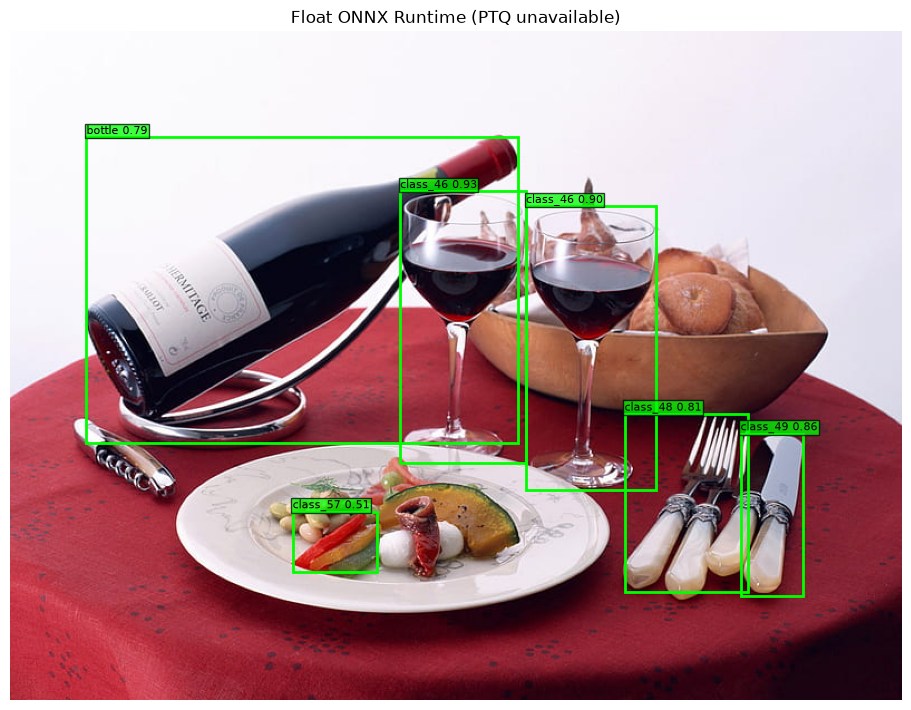

Float detections: 6
Quantized plot unavailable because Aidge PTQ did not complete.


In [11]:
COCO_NAMES = {
    1: "person", 2: "bicycle", 3: "car", 4: "motorcycle", 6: "bus",
    8: "truck", 10: "traffic light", 16: "bird", 17: "cat", 18: "dog",
    44: "bottle", 62: "chair", 72: "tv", 73: "laptop", 77: "cell phone",
}


def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def cxcywh_to_xyxy(boxes):
    cx, cy, width, height = np.moveaxis(boxes, -1, 0)
    return np.stack(
        [cx - width / 2, cy - height / 2, cx + width / 2, cy + height / 2],
        axis=-1,
    )


def top_detections(outputs, image_size, k=20, threshold=0.5):
    logits = outputs["labels"][0]
    boxes = outputs["dets"][0]
    scores = sigmoid(logits).reshape(-1)
    order = np.argsort(scores)[::-1]
    classes = logits.shape[-1]
    width, height = image_size
    scale = np.array([width, height, width, height], dtype=np.float32)
    boxes = cxcywh_to_xyxy(boxes) * scale
    result = []
    for flat_index in order:
        score = float(scores[flat_index])
        if score < threshold:
            break
        box_index = int(flat_index // classes)
        label = int(flat_index % classes)
        result.append((score, label, boxes[box_index]))
        if len(result) == k:
            break
    return result


def draw(ax, image, detections, title, color):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
    for score, label, box in detections:
        x0, y0, x1, y1 = box
        rectangle = patches.Rectangle(
            (x0, y0), x1 - x0, y1 - y0,
            linewidth=2, edgecolor=color, facecolor="none",
        )
        ax.add_patch(rectangle)
        ax.text(
            x0, max(0, y0 - 3),
            f"{COCO_NAMES.get(label, f'class_{label}')} {score:.2f}",
            fontsize=8, color="black",
            bbox={"facecolor": color, "alpha": 0.75, "pad": 1},
        )


ort_detections = top_detections(ort_outputs, original_size)
if quant_outputs is not None:
    quant_detections = top_detections(quant_outputs, original_size)
    figure, axes = plt.subplots(1, 2, figsize=(17, 8), constrained_layout=True)
    draw(axes[0], test_image, ort_detections, "Float ONNX Runtime", "lime")
    draw(axes[1], test_image, quant_detections, f"Aidge PTQ ({NB_BITS}-bit)", "cyan")
    plt.show()
    print("Float detections:", len(ort_detections))
    print("Quantized detections:", len(quant_detections))
else:
    figure, axis = plt.subplots(1, 1, figsize=(9, 8), constrained_layout=True)
    draw(axis, test_image, ort_detections, "Float ONNX Runtime (PTQ unavailable)", "lime")
    plt.show()
    print("Float detections:", len(ort_detections))
    print("Quantized plot unavailable because Aidge PTQ did not complete.")

## Optional: inspect every node dtype

In [12]:
# This is intentionally separate because LW-DETR has many nodes.
# Uncomment when detailed inspection is needed.
# dtype_report(quantized_model, "Quantized model — every node", show_nodes=True)